# Work spans from work locations
For each individual, the first and the last year found on their work locations (Wikidata P937), and how many new work spans this would bring to the database.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

apply_style()

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
STATEMENTS = Path('../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/parts/statements')
MIN_BORN = 1_000  # centuries with fewer births are left out of the per-century table
MAX_SPAN = 80  # years shown in the span histogram

pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_tbl_hide_column_data_types(True)

polars.config.Config

## Data
Every non-deprecated work-location statement with the year of its start (P580), end (P582) and point in time (P585). Every individual of the database with their birth year and their current first and last work years.

In [2]:
connection = duckdb.connect(DB_PATH, read_only=True)
date = 'STRUCT(time VARCHAR, precision INTEGER)'
year = lambda field: f"TRY_CAST(regexp_extract({field}.time, '^[+-]?\\d+') AS INTEGER)"
work_locations = connection.sql(f'''
    SELECT qid, target, {year('start')} AS start_year, {year('"end"')} AS end_year, {year('point_in_time')} AS point_in_time_year
    FROM read_json('{STATEMENTS}/*.json', columns = {{qid: 'VARCHAR', property: 'VARCHAR', target: 'VARCHAR', rank: 'VARCHAR',
                                                       start: '{date}', "end": '{date}', point_in_time: '{date}'}})
    WHERE property = 'P937' AND rank <> 'deprecated'
''').pl()
individuals = connection.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth, first_work_date.year AS db_first_work, last_work_date.year AS db_last_work
    FROM individual_enriched
''').pl()
assert individuals['qid'].is_unique
assert work_locations['qid'].is_in(individuals['qid'].implode()).all()
print(f'{work_locations.height:,} work-location statements of {work_locations["qid"].n_unique():,} individuals; {individuals.height:,} individuals in the database')
work_locations.drop_nulls('start_year').sample(5, seed=0)

587,713 work-location statements of 452,295 individuals; 13,002,897 individuals in the database


qid,target,start_year,end_year,point_in_time_year
"""Q16854395""","""Q2766547""",1705,1706,null
"""Q19756277""","""Q36600""",1857,1893,null
"""Q18634804""","""Q649""",1913,1917,null
"""Q104385897""","""Q239""",1856,1861,null
"""Q25930289""","""Q1726""",1876,1880,null


### First and last year of work per individual
The earliest and the latest of all the dates on all their work locations.

In [3]:
dates = pl.col('start_year', 'end_year', 'point_in_time_year')
spans = (
    work_locations.group_by('qid')
    .agg(
        pl.min_horizontal(dates.min()).alias('first_work'),
        pl.max_horizontal(dates.max()).alias('last_work'),
        (pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null()).sum().alias('full_periods'),
    )
    .with_columns((pl.col('last_work') - pl.col('first_work')).alias('span'))
    .join(individuals, on='qid')
)
assert spans.height == work_locations['qid'].n_unique()
assert (spans['span'].drop_nulls() >= 0).all()
spans.drop_nulls('first_work').sample(5, seed=0)

qid,first_work,last_work,full_periods,span,birth,db_first_work,db_last_work
"""Q15492697""",1691,1741,1,50,1670,1731,1731
"""Q1870792""",1922,1931,1,9,1896,1928,1949
"""Q17516183""",1658,1668,2,10,1635,1650,1670
"""Q104587422""",2001,2001,0,0,null,null,null
"""Q24412871""",1914,1914,0,0,1887,1919,1940


## How many individuals get a work span

median span: 23 years; database individuals with a first work year: 4,535,688


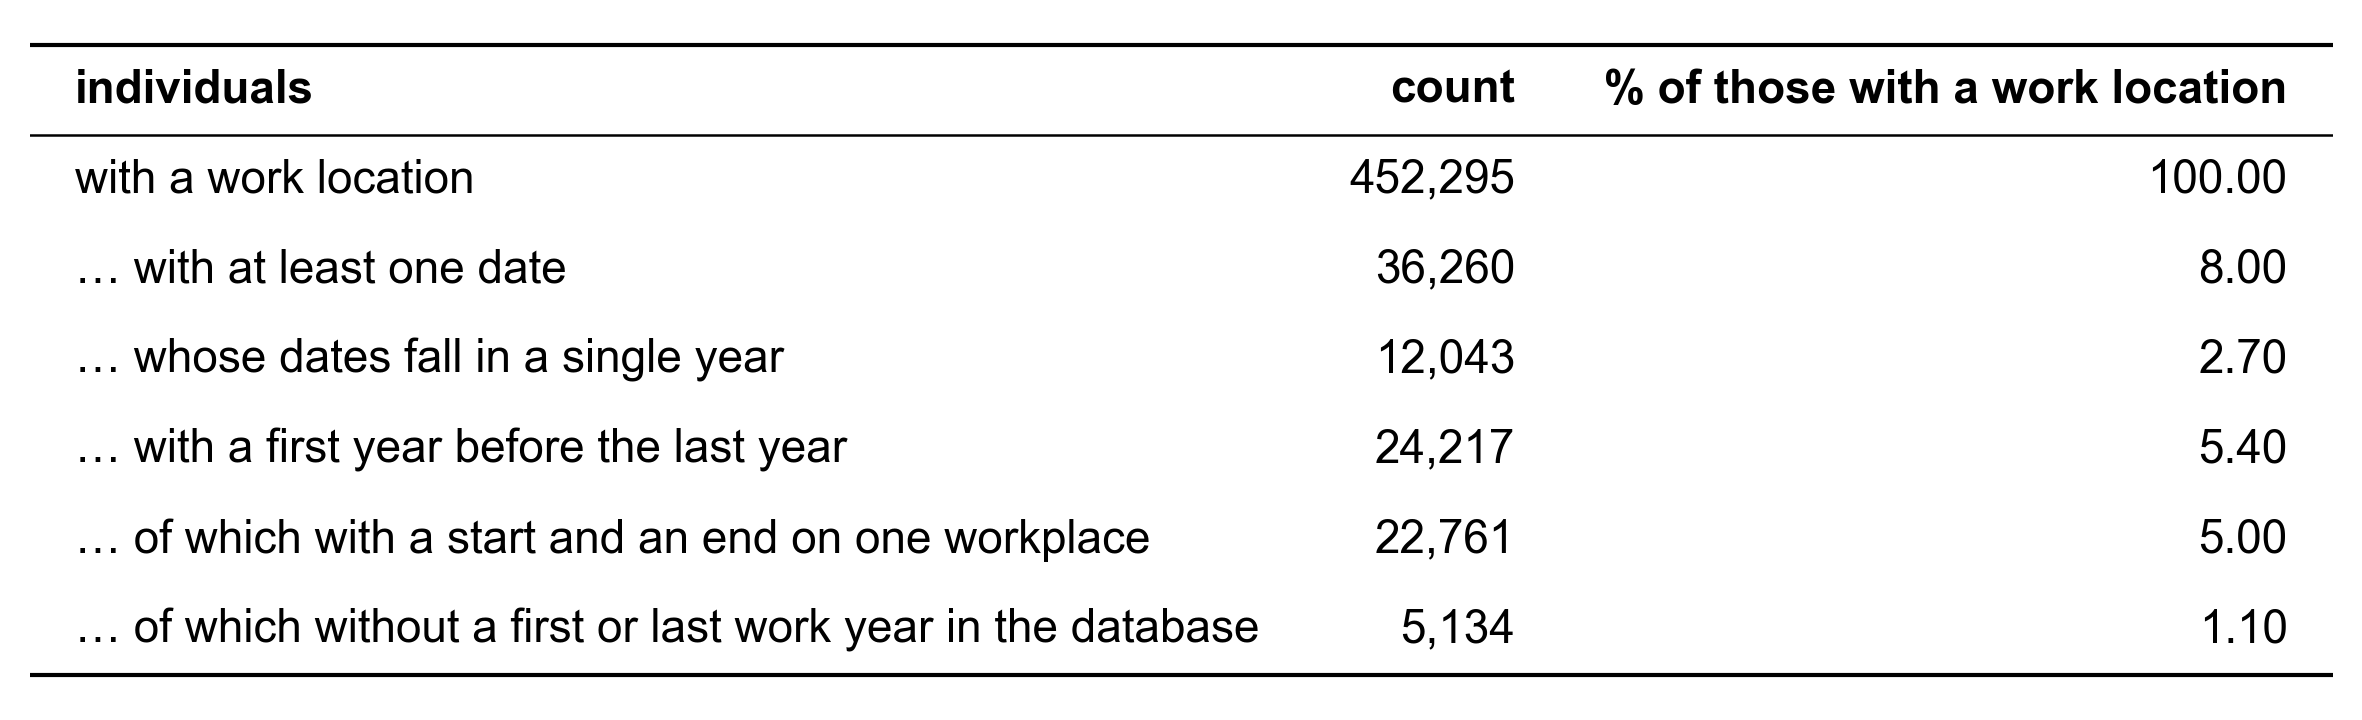

In [4]:
with_span = spans.filter(pl.col('span') > 0)
new = with_span.filter(pl.col('db_first_work').is_null() | pl.col('db_last_work').is_null())
funnel = pl.DataFrame({
    'individuals': [
        'with a work location',
        '… with at least one date',
        '… whose dates fall in a single year',
        '… with a first year before the last year',
        '… of which with a start and an end on one workplace',
        '… of which without a first or last work year in the database',
    ],
    'count': [
        spans.height,
        spans['first_work'].is_not_null().sum(),
        (spans['span'] == 0).sum(),
        with_span.height,
        (with_span['full_periods'] > 0).sum(),
        new.height,
    ],
}).with_columns((100 * pl.col('count') / spans.height).round(1).alias('% of those with a work location'))
print(f'median span: {with_span["span"].median():.0f} years; database individuals with a first work year: {individuals["db_first_work"].is_not_null().sum():,}')
show_table(funnel)

### Agreement with the work years already in the database
For the individuals who have both, the gap between the work-location year and the database year (work location minus database).

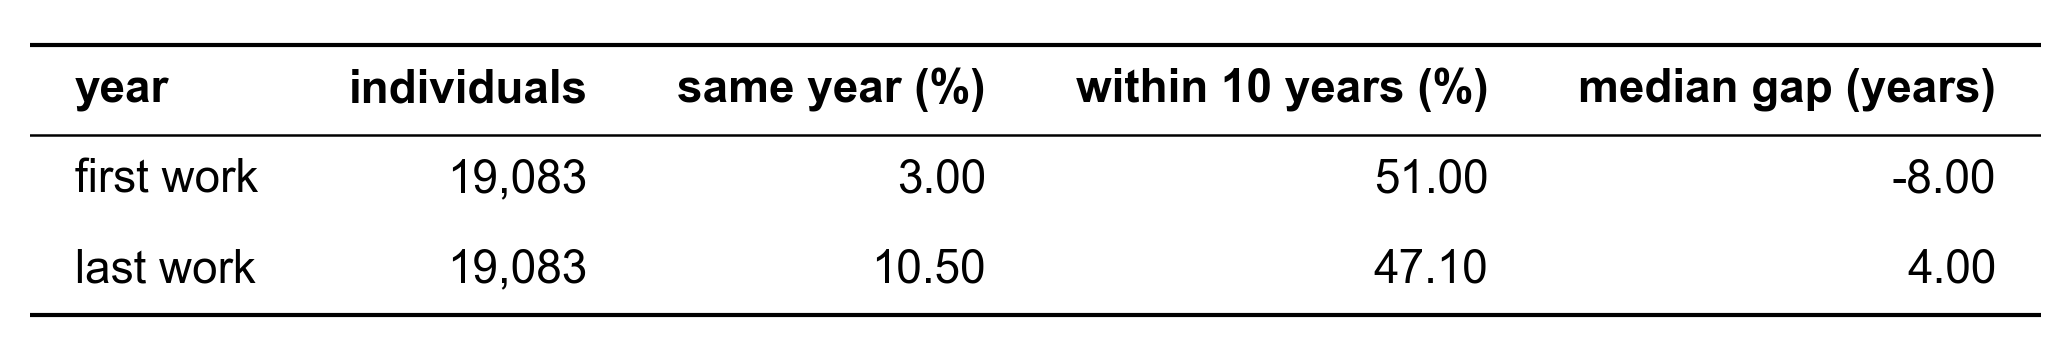

In [5]:
both = with_span.drop_nulls(['db_first_work', 'db_last_work'])
agreement = pl.DataFrame({
    'year': ['first work', 'last work'],
    'individuals': [both.height, both.height],
    'same year (%)': [(100 * (both['first_work'] == both['db_first_work']).mean()), (100 * (both['last_work'] == both['db_last_work']).mean())],
    'within 10 years (%)': [(100 * ((both['first_work'] - both['db_first_work']).abs() <= 10).mean()), (100 * ((both['last_work'] - both['db_last_work']).abs() <= 10).mean())],
    'median gap (years)': [(both['first_work'] - both['db_first_work']).median(), (both['last_work'] - both['db_last_work']).median()],
}).with_columns(pl.col('same year (%)', 'within 10 years (%)').round(1))
show_table(agreement)

## By century of birth
Individuals without a birth year are left out here.

2,473 individuals with a work span but no birth year left out


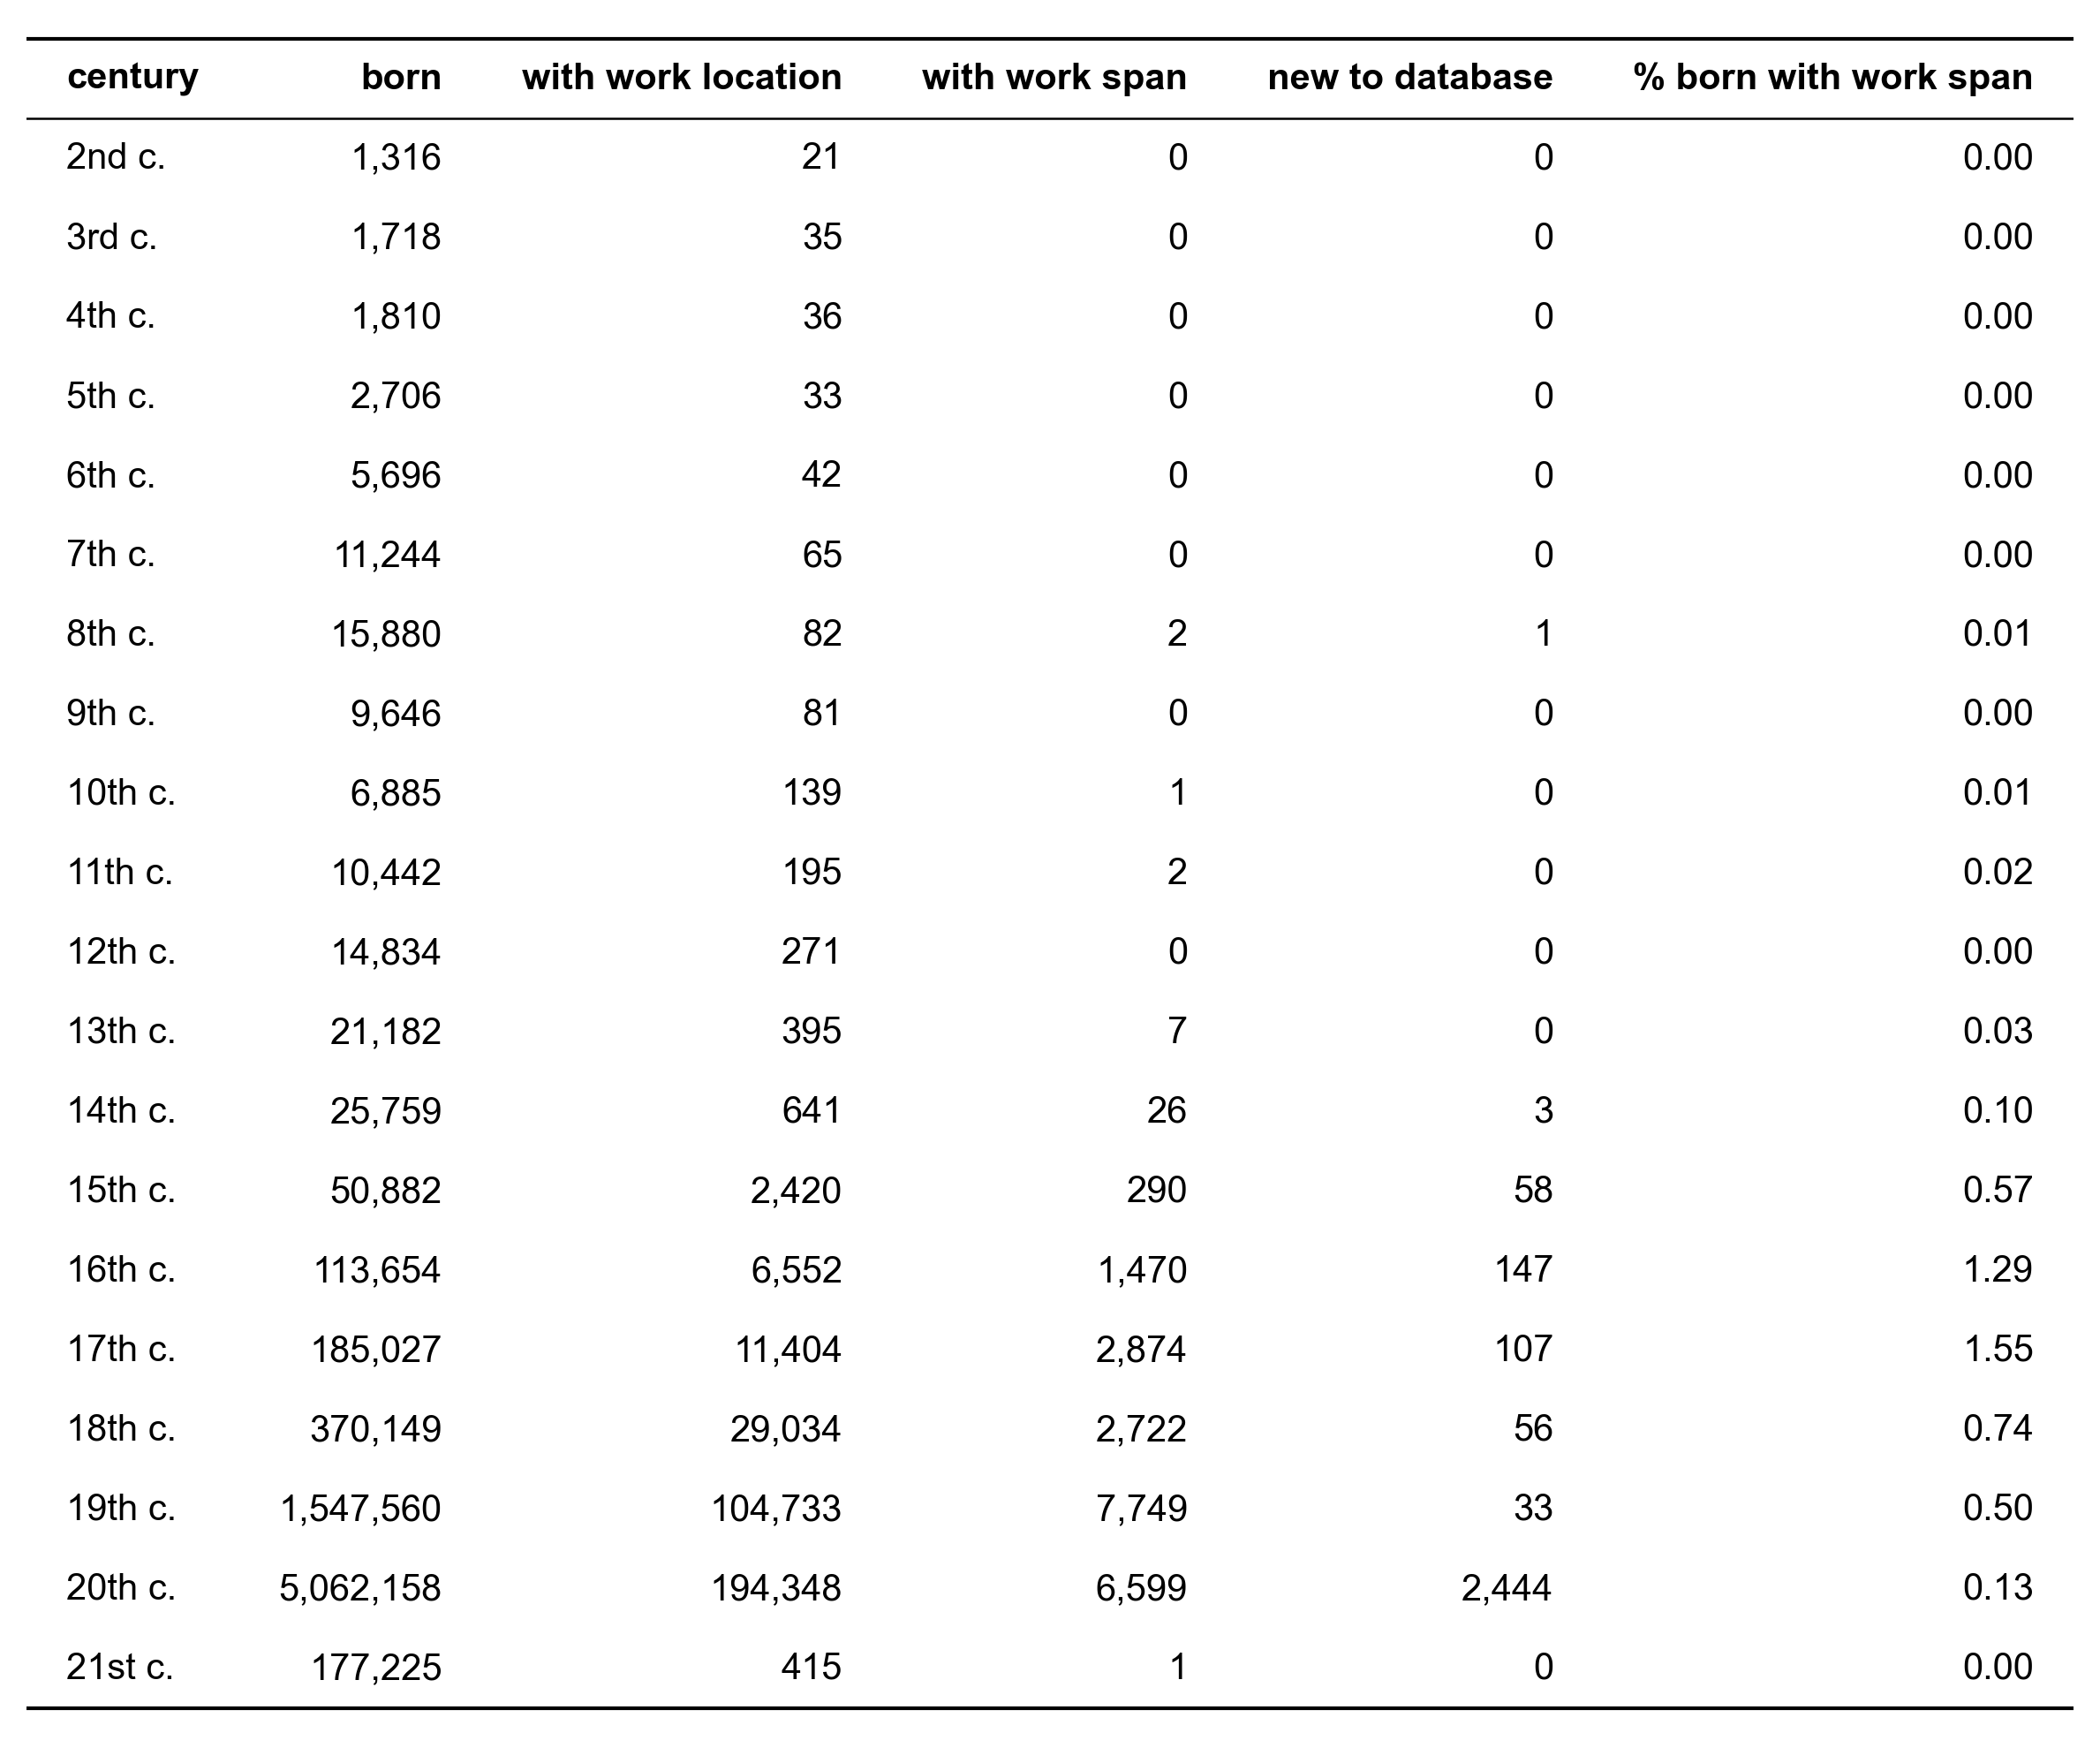

In [6]:
def century(year):
    number = abs(year) // 100 + 1 if year >= 0 else (abs(year) - 1) // 100 + 1
    suffix = 'th' if 10 <= number % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')
    return f"{number}{suffix} c.{' BC' if year < 0 else ''}"


order = pl.when(pl.col('birth') >= 0).then(pl.col('birth') // 100).otherwise(-((-pl.col('birth') - 1) // 100) - 1).alias('order')
born = individuals.drop_nulls('birth').group_by(order).agg(pl.len().alias('born'), pl.col('birth').first())
per_century = (
    born.join(spans.drop_nulls('birth').group_by(order).len('with work location'), on='order', how='left')
    .join(with_span.drop_nulls('birth').group_by(order).len('with work span'), on='order', how='left')
    .join(new.drop_nulls('birth').group_by(order).len('new to database'), on='order', how='left')
    .fill_null(0)
    .filter(pl.col('born') >= MIN_BORN)
    .sort('order')
    .select(
        pl.col('birth').map_elements(century, return_dtype=pl.String).alias('century'),
        'born', 'with work location', 'with work span', 'new to database',
        (100 * pl.col('with work span') / pl.col('born')).round(2).alias('% born with work span'),
    )
)
print(f'{with_span["birth"].null_count():,} individuals with a work span but no birth year left out')
show_table(per_century, font_size=10)

### Figure 1: Length of the work spans (first to last year on work locations)

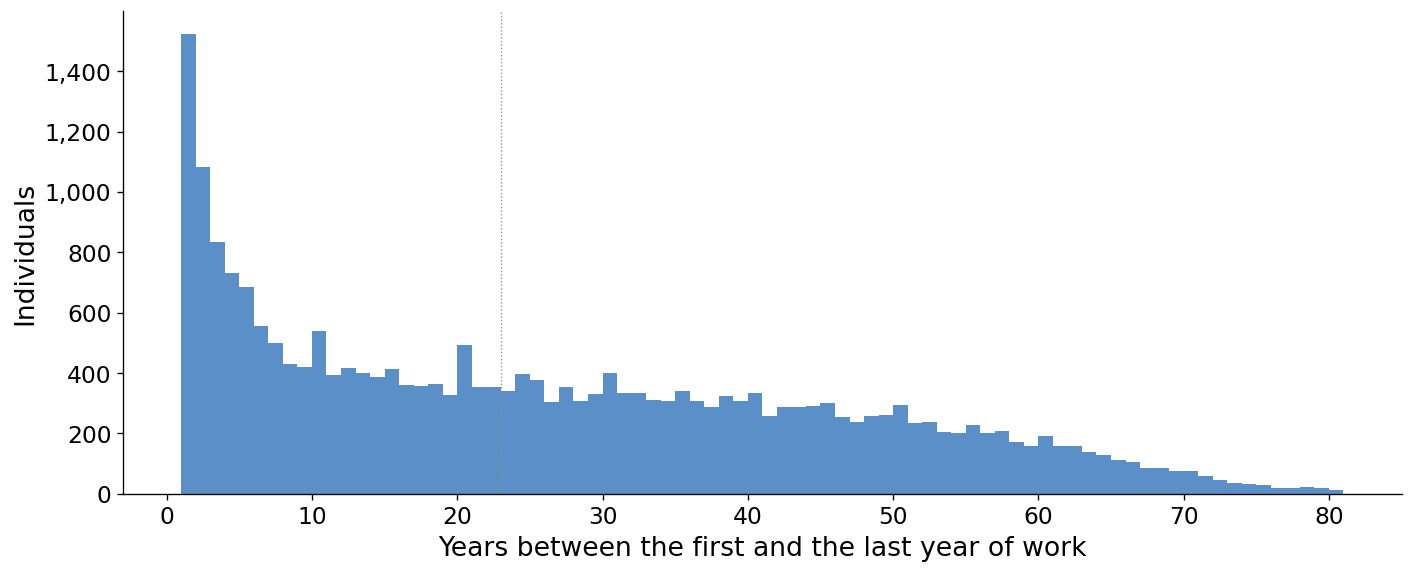

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.hist(with_span['span'].filter(with_span['span'] <= MAX_SPAN), bins=range(1, MAX_SPAN + 2), color=BLUE)
ax.axvline(with_span['span'].median(), **REFERENCE_LINE)
ax.set_xlabel('Years between the first and the last year of work')
ax.set_ylabel('Individuals')
ax.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()